In [1]:
import pandas as pd
import numpy as np
URL = r'C:\python\srh python\Statistics-and-Machine-Learning\Week-3\Lab-Assignments\diabetes.csv'
df = pd.read_csv(URL)

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)


Dataset loaded: 768 rows x 9 columns
Shape: (768, 9)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [2]:
print(df['Outcome'].unique())
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:df[col] = df[col].replace(0, np.nan)
print('Missing values after replacing 0s:')
print(df.isnull().sum())

[1 0]
Missing values after replacing 0s:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [3]:
print("Describe", df.describe())


Describe        Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  763.000000     733.000000     541.000000  394.000000   
mean      3.845052  121.686763      72.405184      29.153420  155.548223   
std       3.369578   30.535641      12.382158      10.476982  118.775855   
min       0.000000   44.000000      24.000000       7.000000   14.000000   
25%       1.000000   99.000000      64.000000      22.000000   76.250000   
50%       3.000000  117.000000      72.000000      29.000000  125.000000   
75%       6.000000  141.000000      80.000000      36.000000  190.000000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  757.000000                768.000000  768.000000  768.000000  
mean    32.457464                  0.471876   33.240885    0.348958  
std      6.924988                  0.331329   11.760232    0.476951  
min     18.200000         

In [4]:
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    df[col] = df[col].fillna(df[col].median())


In [5]:
X = df.drop('Outcome', axis = 1)
y = df['Outcome']
print(f'Shape of X:, {X.shape}')
print(f'Shape of y:, {y.shape}')

Shape of X:, (768, 8)
Shape of y:, (768,)


In [6]:
import sklearn.model_selection as ms
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

Train shape: (614, 8)
Test shape: (154, 8)


In [7]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf_model_50 = RandomForestClassifier(n_estimators=50, random_state=42, max_depth=5)
rf_model_50.fit(X_train, y_train)

rf_model_100 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_100.fit(X_train, y_train)

rf_model_200 = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model_200.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [8]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = rf_model_50.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_rep)

sample = X_test.iloc[0:1]
prediction = rf_model_50.predict(sample)

sample_dict = sample.iloc[0].to_dict()
print(f"\nDiabetic: {sample_dict}")
print(f"Status: {'Diabetic' if prediction[0] == 1 else 'Non-Diabetic'}")

Accuracy: 0.73

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.86      0.81       100
           1       0.66      0.50      0.57        54

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.69       154
weighted avg       0.73      0.73      0.72       154


Diabetic: {'Pregnancies': 7.0, 'Glucose': 159.0, 'BloodPressure': 64.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 27.4, 'DiabetesPedigreeFunction': 0.294, 'Age': 40.0}
Status: Diabetic


In [9]:
y_pred = rf_model_100.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_rep)

sample = X_test.iloc[0:1]
prediction = rf_model_100.predict(sample)

sample_dict = sample.iloc[0].to_dict()
print(f"\nDiabetic: {sample_dict}")
print(f"Status: {'Diabetic' if prediction[0] == 1 else 'Non-Diabetic'}")

Accuracy: 0.78

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.88      0.84       100
           1       0.73      0.59      0.65        54

    accuracy                           0.78       154
   macro avg       0.76      0.74      0.75       154
weighted avg       0.77      0.78      0.77       154


Diabetic: {'Pregnancies': 7.0, 'Glucose': 159.0, 'BloodPressure': 64.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 27.4, 'DiabetesPedigreeFunction': 0.294, 'Age': 40.0}
Status: Diabetic


In [10]:
y_pred = rf_model_200.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_rep)

sample = X_test.iloc[0:1]
prediction = rf_model_200.predict(sample)

sample_dict = sample.iloc[0].to_dict()
print(f"\nDiabetic: {sample_dict}")
print(f"Status: {'Diabetic' if prediction[0] == 1 else 'Non-Diabetic'}")

Accuracy: 0.74

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


Diabetic: {'Pregnancies': 7.0, 'Glucose': 159.0, 'BloodPressure': 64.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 27.4, 'DiabetesPedigreeFunction': 0.294, 'Age': 40.0}
Status: Diabetic


In [11]:
models = {50: rf_model_50, 100: rf_model_100, 200: rf_model_200}

best_lr = max(models, key=lambda lr: accuracy_score(y_test, models[lr].predict(X_test)))
best_rf_model = models[best_lr]

print(f"Best learning_rate: {best_lr}")
print(f"Best test accuracy: {accuracy_score(y_test, best_rf_model.predict(X_test)):.4f}")

Best learning_rate: 100
Best test accuracy: 0.7792


In [12]:
gf_lr_001 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.01, random_state=42)
gf_lr_001.fit(X_train, y_train)
gf_lr_01 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gf_lr_01.fit(X_train, y_train)
gf_lr_03 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.3, random_state=42)
gf_lr_03.fit(X_train, y_train)


,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [13]:
for lr, model in [(0.01, gf_lr_001), (0.1, gf_lr_01), (0.3, gf_lr_03)]:
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)
    print(f"\nLearning Rate: {lr}")
    print(f"Accuracy: {accuracy:.2f}")
    print("\nClassification Report:\n", classification_rep)


Learning Rate: 0.01
Accuracy: 0.69

Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.87      0.79       100
           1       0.61      0.37      0.46        54

    accuracy                           0.69       154
   macro avg       0.66      0.62      0.62       154
weighted avg       0.68      0.69      0.67       154


Learning Rate: 0.1
Accuracy: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.86      0.82       100
           1       0.68      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.73      0.71      0.72       154
weighted avg       0.75      0.75      0.75       154


Learning Rate: 0.3
Accuracy: 0.73

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.81      0.80       100
           1       0.63      0.59      0.61        54

 

In [14]:
models = {0.01: gf_lr_001, 0.1: gf_lr_01, 0.3: gf_lr_03}

best_lr = max(models, key=lambda lr: accuracy_score(y_test, models[lr].predict(X_test)))
best_gf_model = models[best_lr]

print(f"Best learning_rate: {best_lr}")
print(f"Best test accuracy: {accuracy_score(y_test, best_gf_model.predict(X_test)):.4f}")


Best learning_rate: 0.1
Best test accuracy: 0.7532


In [15]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_metrics(model, X_test, y_test):
    y_pred = model.predict(X_test)
    return {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred)
    }

comparison_table = pd.DataFrame({
    'Random Forest': get_metrics(best_rf_model, X_test, y_test),
    'Gradient Boosting': get_metrics(best_gf_model, X_test, y_test)
}).T   # .T so rows = models, columns = metrics (as the assignment asks)

print(comparison_table.round(4))
comparison_table.round(4)


                   Accuracy  Precision  Recall  F1-score
Random Forest        0.7792     0.7273  0.5926    0.6531
Gradient Boosting    0.7532     0.6818  0.5556    0.6122


,Accuracy,Precision,Recall,F1-score
Random Forest,0.7792,0.7273,0.5926,0.6531
Gradient Boosting,0.7532,0.6818,0.5556,0.6122


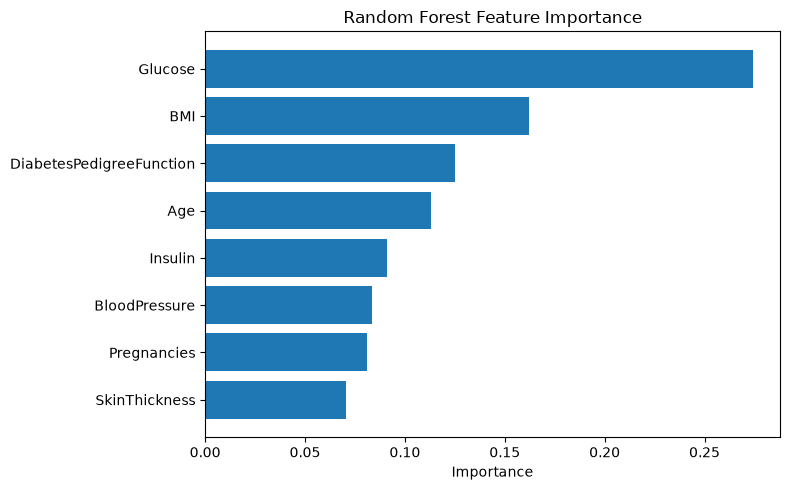

In [16]:
import matplotlib.pyplot as plt
rf_importance = pd.Series(best_rf_model.feature_importances_, index = X_train.columns).sort_values(ascending=True)

plt.figure(figsize = (8, 5))
plt.barh(rf_importance.index, rf_importance.values)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


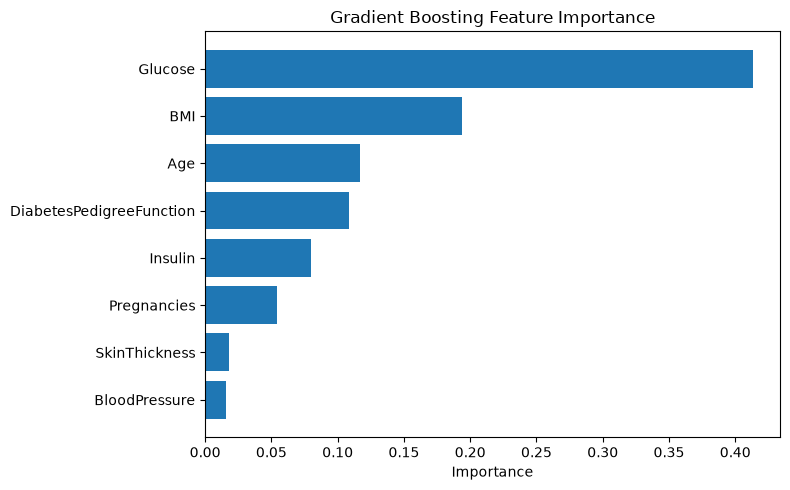

In [17]:
gb_importance = pd.Series(best_gf_model.feature_importances_, index = X_train.columns).sort_values(ascending=True)

plt.figure(figsize = (8, 5))
plt.barh(gb_importance.index, gb_importance.values)
plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()  
plt.show()

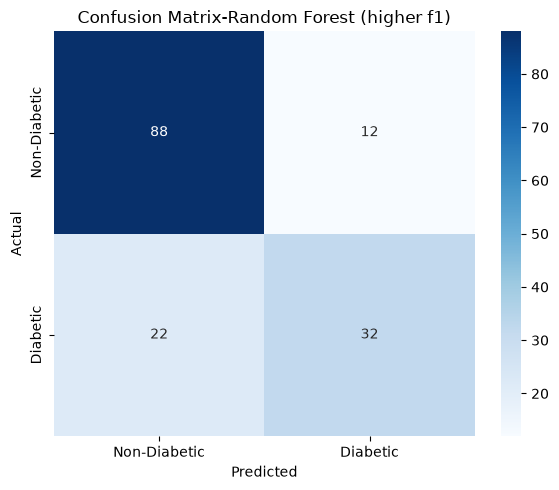

In [19]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

rf_f1 = f1_score(y_test, best_rf_model.predict(X_test))
gb_f1 = f1_score(y_test, best_gf_model.predict(X_test))

if rf_f1 >= gb_f1:
    best_model, best_name = best_rf_model, 'Random Forest'
else:
    best_model, best_name = best_gf_model, 'Gradient Boosting'

cm = confusion_matrix(y_test, best_model.predict(X_test))
plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
plt.title(f'Confusion Matrix-{best_name} (higher f1)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()  

1.The most important Feature for Random forest and GradientBoosting is Glucose, this finding was achieved via visualization
2.I changed n_estimators(50,100,200) the accuracy actually changes from 74 to 78% and for Gradient Boosting I changed learning_rate(0.01,0.1,0.3) and it had more effect, a very small learning rate(0.01) learned too slowly, while the moderate one gave best result.
3.The model struggles most with finding the actual diabetic patients, as it misses a good number of real diabetic the false negatives labeling them as healthy
4.The model looks at many past patients and their health numbers, learn the pattern that usually go with diabetes and then guess whether a person is likely to have diabetes.
5.Random forest perfomed better here with F1 score of 65% to Gradient Boosting at 61%.